In [1]:
from pathlib import Path
import pandas as pd

# Load processed global ads dataset
candidates = [
    Path("data/processed/global_ads_performance_dataset_processed.csv"),
    Path("../data/processed/global_ads_performance_dataset_processed.csv"),
]

csv_path = next((p for p in candidates if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError(
        "Could not find processed CSV. Tried: " + ", ".join(str(p) for p in candidates)
    )

df = pd.read_csv(csv_path)
print("Loaded from:", csv_path.resolve())
print("Shape:", df.shape)

# Show all unique industries
unique_industries = sorted(
    df["industry"].dropna().astype(str).str.strip().unique().tolist()
)
print("\nUnique industries:")
for industry in unique_industries:
    print(f"- {industry}")

Loaded from: /Users/Carys/Documents/Github/ads-analysis/data/processed/global_ads_performance_dataset_processed.csv
Shape: (1800, 14)

Unique industries:
- E-commerce
- EdTech
- Fintech
- Healthcare
- SaaS



Correlation matrix - Google Ads


,ad_spend,clicks,conversions,revenue,ROAS,CPC,CPA,CTR
ad_spend,1.000,0.830,0.592,0.500,-0.225,0.497,0.290,0.421
clicks,0.830,1.000,0.750,0.615,0.005,0.026,0.049,0.504
conversions,0.592,0.750,1.000,0.811,0.313,-0.012,-0.381,0.360
revenue,0.500,0.615,0.811,1.000,0.532,0.012,-0.294,0.277
ROAS,-0.225,0.005,0.313,0.532,1.000,-0.460,-0.534,-0.046
CPC,0.497,0.026,-0.012,0.012,-0.460,1.000,0.490,0.032
CPA,0.290,0.049,-0.381,-0.294,-0.534,0.490,1.000,0.053
CTR,0.421,0.504,0.360,0.277,-0.046,0.032,0.053,1.000



Correlation matrix - Meta Ads


,ad_spend,clicks,conversions,revenue,ROAS,CPC,CPA,CTR
ad_spend,1.000,0.798,0.631,0.530,-0.222,0.504,0.212,0.405
clicks,0.798,1.000,0.811,0.659,0.049,0.008,-0.048,0.507
conversions,0.631,0.811,1.000,0.803,0.274,-0.003,-0.373,0.418
revenue,0.530,0.659,0.803,1.000,0.494,0.015,-0.309,0.345
ROAS,-0.222,0.049,0.274,0.494,1.000,-0.490,-0.535,0.022
CPC,0.504,0.008,-0.003,0.015,-0.490,1.000,0.494,0.009
CPA,0.212,-0.048,-0.373,-0.309,-0.535,0.494,1.000,-0.021
CTR,0.405,0.507,0.418,0.345,0.022,0.009,-0.021,1.000



Correlation matrix - TikTok Ads


,ad_spend,clicks,conversions,revenue,ROAS,CPC,CPA,CTR
ad_spend,1.000,0.801,0.648,0.537,-0.265,0.534,0.220,0.360
clicks,0.801,1.000,0.811,0.653,0.001,0.038,-0.042,0.483
conversions,0.648,0.811,1.000,0.821,0.240,0.021,-0.363,0.426
revenue,0.537,0.653,0.821,1.000,0.467,0.036,-0.287,0.316
ROAS,-0.265,0.001,0.240,0.467,1.000,-0.527,-0.530,-0.023
CPC,0.534,0.038,0.021,0.036,-0.527,1.000,0.534,-0.027
CPA,0.220,-0.042,-0.363,-0.287,-0.530,0.534,1.000,-0.113
CTR,0.360,0.483,0.426,0.316,-0.023,-0.027,-0.113,1.000


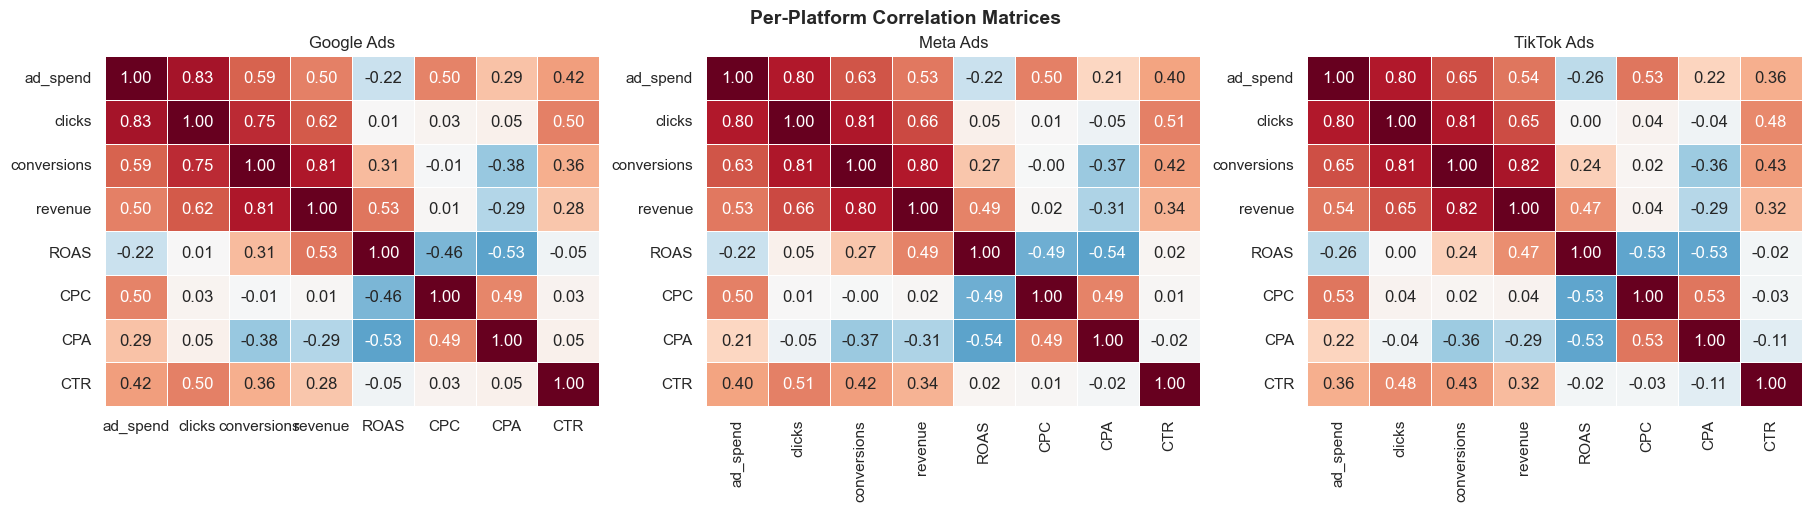

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Correlation matrices for each platform
metrics = ["ad_spend", "clicks", "conversions", "revenue", "ROAS", "CPC", "CPA", "CTR"]
platforms = sorted(df["platform"].dropna().unique())

platform_corr = {}
for platform in platforms:
    subset = df[df["platform"] == platform][metrics].copy()
    platform_corr[platform] = subset.corr(numeric_only=True)

# Display matrix values in text form
for platform, corr_matrix in platform_corr.items():
    print(f"\nCorrelation matrix - {platform}")
    display(corr_matrix.round(3))

# Plot heatmaps side-by-side
sns.set_theme(style="white")
fig, axes = plt.subplots(1, len(platforms), figsize=(6 * len(platforms), 5), constrained_layout=True)

if len(platforms) == 1:
    axes = [axes]

for ax, platform in zip(axes, platforms):
    sns.heatmap(
        platform_corr[platform],
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        annot=True,
        fmt=".2f",
        linewidths=0.5,
        cbar=False,
        ax=ax,
    )
    ax.set_title(platform)

fig.suptitle("Per-Platform Correlation Matrices", fontsize=14, weight="bold")
plt.show()

Diminishing Returns Summary (Spend -> Revenue Slope):


,platform,low_spend_slope,high_spend_slope,slope_drop_pct,diminishing_returns
1,Meta Ads,6.812,2.305,66.165,True
2,TikTok Ads,8.368,3.596,57.033,True
0,Google Ads,4.919,2.165,55.977,True


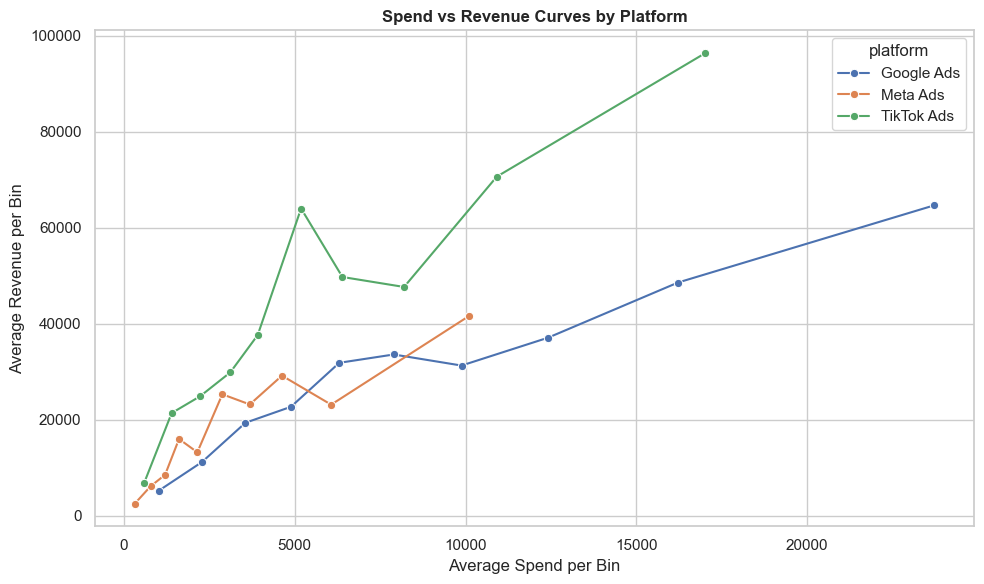

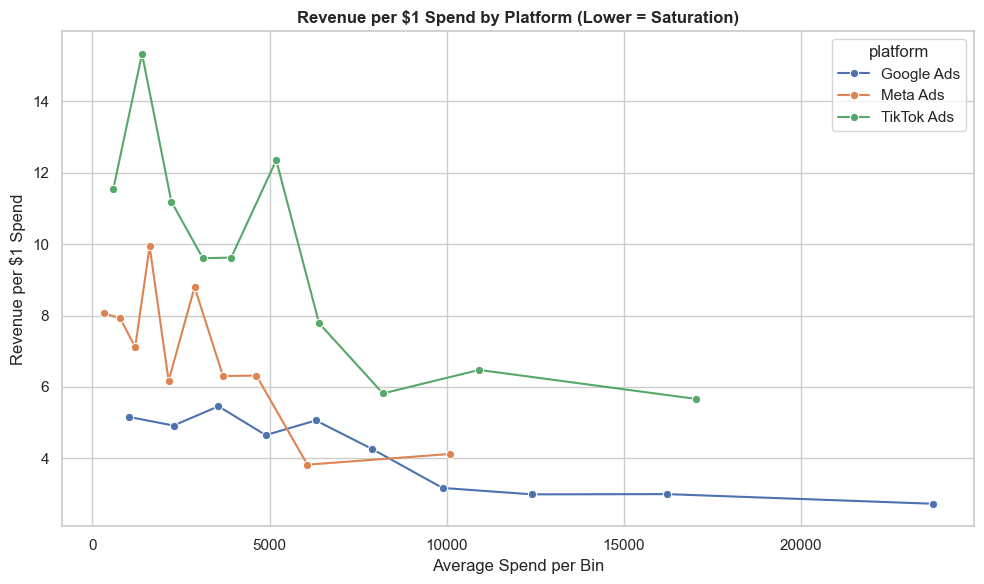

In [3]:
import numpy as np

# 2) Spend vs Revenue relationship (diminishing returns check)
# Approach:
# - Split each platform's campaigns into spend bins (low -> high)
# - Compare revenue-vs-spend slope in low-spend vs high-spend half

engine_rows = []
curve_rows = []

for platform, g in df.groupby("platform"):
    work = g[["ad_spend", "revenue"]].dropna().copy()

    # Bin by spend; duplicates='drop' avoids errors when values repeat heavily
    work["spend_bin"] = pd.qcut(work["ad_spend"], q=10, duplicates="drop")
    binned = (
        work.groupby("spend_bin", observed=True)
        .agg(mean_spend=("ad_spend", "mean"), mean_revenue=("revenue", "mean"), n=("revenue", "size"))
        .reset_index(drop=True)
        .sort_values("mean_spend")
    )

    binned["platform"] = platform
    binned["revenue_per_dollar"] = binned["mean_revenue"] / binned["mean_spend"]
    curve_rows.append(binned)

    # Slope in lower vs higher spend ranges
    midpoint = len(binned) // 2
    low = binned.iloc[:midpoint]
    high = binned.iloc[midpoint:]

    if len(low) >= 2 and len(high) >= 2:
        low_slope = np.polyfit(low["mean_spend"], low["mean_revenue"], 1)[0]
        high_slope = np.polyfit(high["mean_spend"], high["mean_revenue"], 1)[0]
        slope_drop_pct = ((low_slope - high_slope) / abs(low_slope) * 100) if low_slope != 0 else np.nan
    else:
        low_slope, high_slope, slope_drop_pct = np.nan, np.nan, np.nan

    engine_rows.append(
        {
            "platform": platform,
            "low_spend_slope": low_slope,
            "high_spend_slope": high_slope,
            "slope_drop_pct": slope_drop_pct,
            "diminishing_returns": bool(high_slope < low_slope) if pd.notna(low_slope) and pd.notna(high_slope) else None,
        }
    )

engine_summary = pd.DataFrame(engine_rows).sort_values("slope_drop_pct", ascending=False)
curve_df = pd.concat(curve_rows, ignore_index=True)

print("Diminishing Returns Summary (Spend -> Revenue Slope):")
display(engine_summary.round(3))

_processed_out = Path("data/processed")
if not _processed_out.exists():
    _processed_out = Path("../data/processed")
_dr_csv = _processed_out / "diminishing_returns_summary.csv"
engine_summary.to_csv(_dr_csv, index=False)
print(f"Saved diminishing returns summary: {_dr_csv.resolve()}")

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=curve_df,
    x="mean_spend",
    y="mean_revenue",
    hue="platform",
    marker="o",
)
plt.title("Spend vs Revenue Curves by Platform", weight="bold")
plt.xlabel("Average Spend per Bin")
plt.ylabel("Average Revenue per Bin")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.lineplot(
    data=curve_df,
    x="mean_spend",
    y="revenue_per_dollar",
    hue="platform",
    marker="o",
)
plt.title("Revenue per $1 Spend by Platform (Lower = Saturation)", weight="bold")
plt.xlabel("Average Spend per Bin")
plt.ylabel("Revenue per $1 Spend")
plt.tight_layout()
plt.show()